In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


In [2]:
import pandas as pd
df=pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
import pandas as pd
df.isnull().sum()
df.isnull().mean()*100
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])
df['HasCabin']=df['Cabin'].notnull().astype(int)
df=df.drop(columns=['Cabin'])
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64

In [4]:
import pandas as pd
df['Survived'].mean()
df['Survived'].value_counts()
df.groupby('Sex')['Survived'].mean()
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [5]:
import pandas as pd
df.groupby('Pclass')['Survived'].mean()
df['AgeGroup']=pd.cut(df['Age'],
                     bins=[0,12,18,35,60,100],
                     labels=['Child','Teen','Young Adult','Adult','Senior'])
df[['Age','AgeGroup']].head()
df.groupby('AgeGroup', observed= True)['Survived'].mean()

AgeGroup
Child          0.579710
Teen           0.428571
Young Adult    0.353271
Adult          0.400000
Senior         0.227273
Name: Survived, dtype: float64

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked', 'HasCabin', 'AgeGroup']


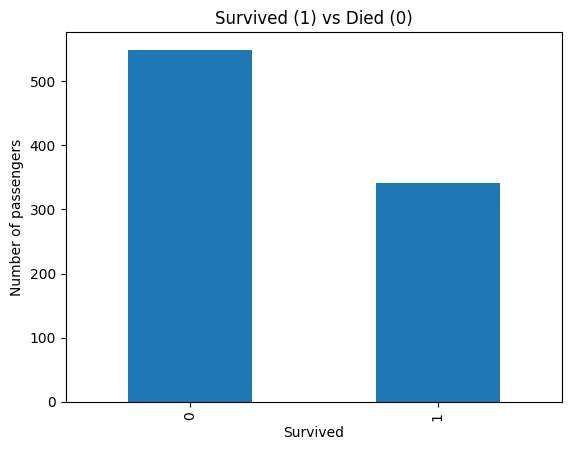

In [6]:
import pandas as pd
print(df.columns.tolist())

import matplotlib.pyplot as plt
df['Survived'].value_counts().plot(kind='bar')
plt.title('Survived (1) vs Died (0)')
plt.xlabel('Survived')
plt.ylabel('Number of passengers')
plt.show()

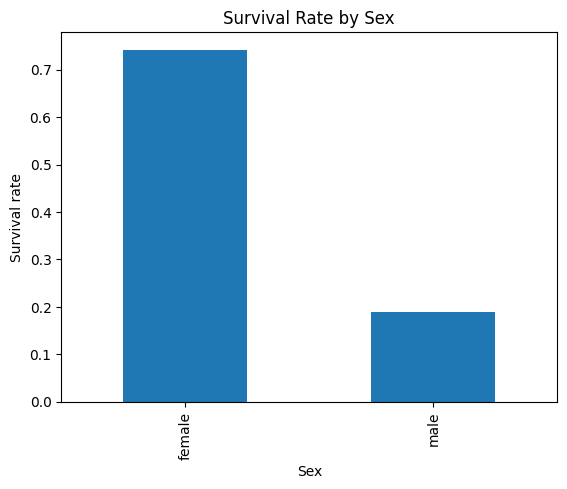

In [7]:
import matplotlib.pyplot as plt
df.groupby('Sex')['Survived'].mean().plot(kind='bar')
plt.title('Survival Rate by Sex')
plt.ylabel('Survival rate')
plt.show()

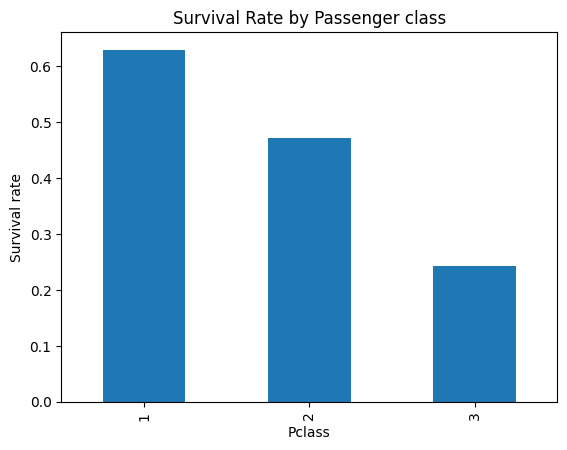

In [8]:
import matplotlib.pyplot as plt
df.groupby('Pclass')['Survived'].mean().plot(kind='bar')
plt.title('Survival Rate by Passenger class')
plt.ylabel('Survival rate')
plt.show()


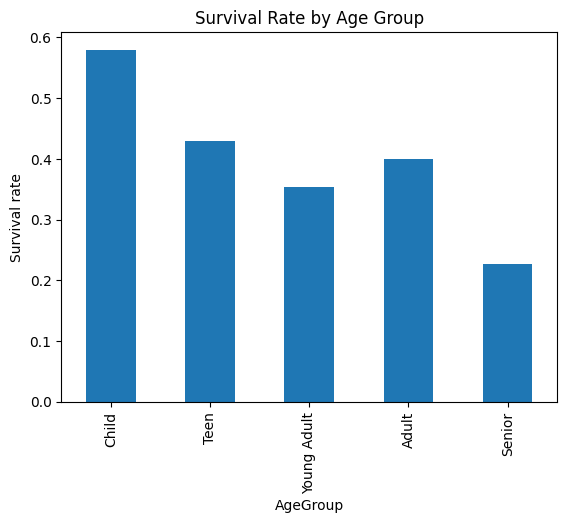

In [9]:
import matplotlib.pyplot as plt
df.groupby('AgeGroup', observed=True)['Survived'].mean().plot(kind='bar')
plt.title('Survival Rate by Age Group')
plt.ylabel('Survival rate')
plt.show()

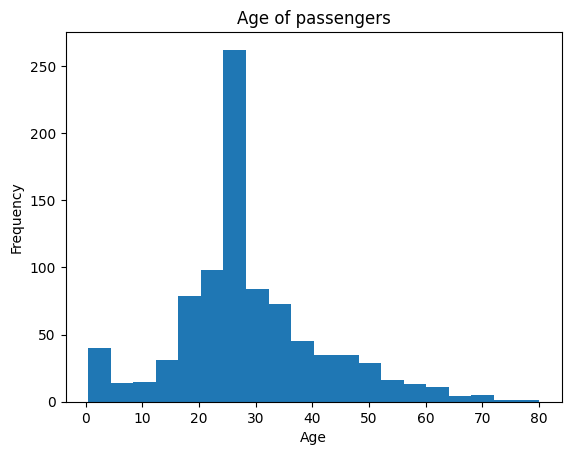

In [10]:
import matplotlib.pyplot as plt
df['Age'].plot(kind='hist',bins=20)
plt.title('Age of passengers')
plt.xlabel('Age')
plt.show()